# Delhi PM2.5 Forecaster — walkthrough
Spatiotemporal forecasting of hourly PM2.5 at **36 Delhi monitoring stations** (+1, +3, +6, +12, +24 h)
with a **Graph Attention + Transformer** network, trained on **real** data (Jan 2023 – Aug 2025).

This notebook walks through the data, the station graph, the models and the results, and runs a live
forecast. The interactive version is the Streamlit app: `streamlit run app/streamlit_app.py`.

In [1]:
import os, sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
sys.path.insert(0, os.path.abspath("src"))
import config as C
from data import AQIData
from models import MODEL_CLASSES, build_model, count_params, Persistence
from evaluate import load_model
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
data = AQIData()
print(f"{data.n_nodes} stations, {len(data.times):,} hours: {data.times[0]} -> {data.times[-1]}")
print(f"Real-data coverage: {data.observed.mean():.1%}")
print({k: len(v) for k, v in data.splits.items()}, "forecast windows (train / val / test)")

36 stations, 23,376 hours: 2023-01-01 00:00:00 -> 2025-08-31 23:00:00
Real-data coverage: 85.7%
{'train': 12905, 'val': 2184, 'test': 5843} forecast windows (train / val / test)


## 1. Data
Real hourly PM2.5 from CPCB, DPCC and IMD stations via the XKDR Air Quality API. Non-physical values and
stuck sensors are removed; missing hours stay missing (an `observed` mask) so models are never trained
or scored on filled-in values. Jan–Mar 2025 is missing network-wide in the source.

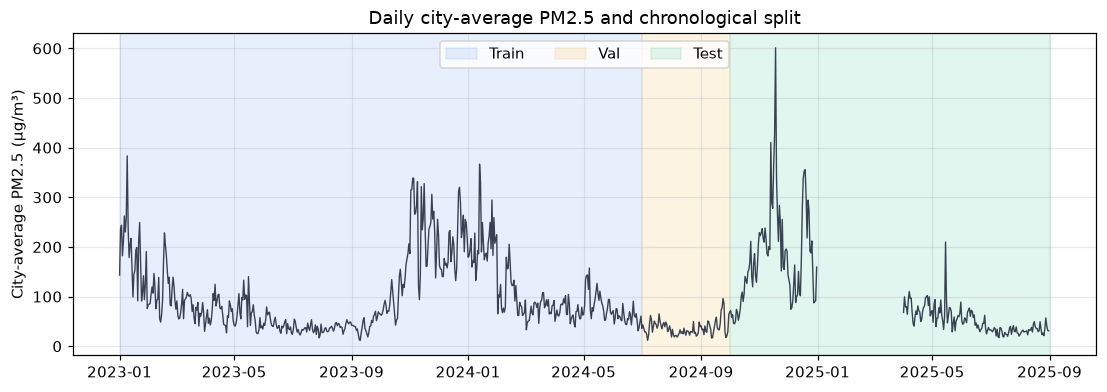

In [2]:
city = pd.DataFrame(data.pm25, index=data.times).mean(axis=1).resample("D").mean()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(city.index, city.values, color="#374151", lw=0.9)
for (a, b, lab, col) in [(C.START, C.TRAIN_END, "Train", "#3B82F6"), (C.TRAIN_END, C.VAL_END, "Val", "#F59E0B"),
                         (C.VAL_END, C.END, "Test", "#10B981")]:
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=col, alpha=0.12, label=lab)
ax.set_ylabel("City-average PM2.5 (µg/m³)"); ax.set_title("Daily city-average PM2.5 and chronological split")
ax.legend(loc="upper center", ncol=3); plt.show()

## 2. Station graph
Each station connects to its 8 nearest neighbours; edge weight `exp(-(d/σ)²)` from the Haversine distance.
The GAT uses `log(weight)` as an attention prior it can learn to override.

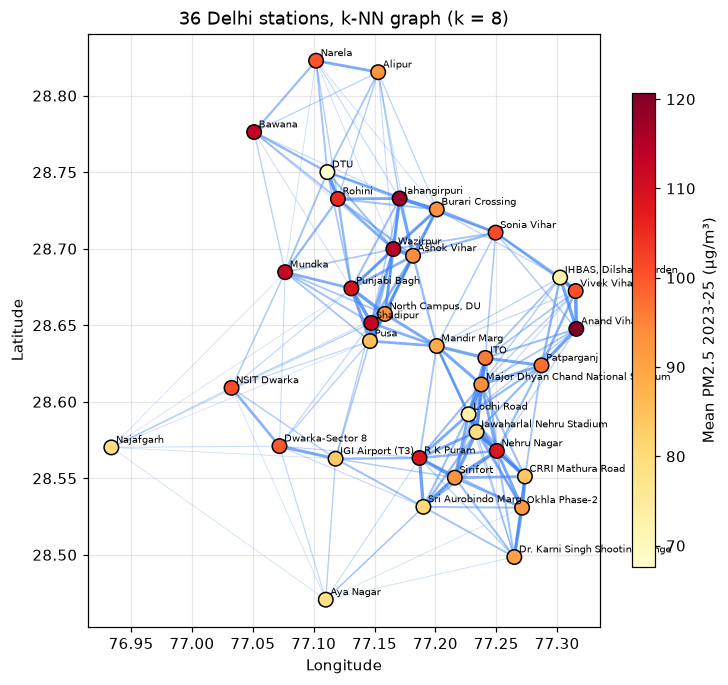

In [3]:
st = data.stations; adj = data.adj.numpy()
fig, ax = plt.subplots(figsize=(7.5, 7))
for i in range(len(st)):
    for j in range(i + 1, len(st)):
        if adj[i, j] > 0:
            ax.plot(st.lon[[i, j]], st.lat[[i, j]], color="#3B82F6", alpha=0.25 + 0.6 * adj[i, j], lw=0.5 + 2 * adj[i, j])
mean_pm = np.nanmean(data.pm25, axis=0)
sc = ax.scatter(st.lon, st.lat, c=mean_pm, cmap="YlOrRd", s=90, edgecolor="k", zorder=3)
for _, r in st.iterrows():
    ax.annotate(r["name"], (r.lon, r.lat), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
plt.colorbar(sc, label="Mean PM2.5 2023-25 (µg/m³)", shrink=0.8)
ax.set_title("36 Delhi stations, k-NN graph (k = 8)"); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); plt.show()

## 3. Models
All neural models share station embeddings and residual forecasting. *Robust* variants use the same
architecture trained with station dropout (15% of stations hidden per sample).

In [4]:
rows = [{"Model": n, "Parameters": f"{count_params(build_model(n, data.n_nodes, 5)):,}"} for n in MODEL_CLASSES]
pd.DataFrame(rows)

,Model,Parameters
0,LSTM,"72,421"
1,Transformer,"74,341"
2,GAT-Transformer,"91,365"
3,Robust LSTM,"72,421"
4,Robust GAT-Transformer,"91,365"


## 4. Results on the unseen test period
Oct–Dec 2024 (winter smog) + Apr–Aug 2025 (summer/monsoon); real observations only; mean ± std over 3 seeds.

In [5]:
ov = pd.read_csv("results/metrics_overall.csv")
ov[["Model", "MAE", "RMSE", "R²", "AQI category acc."]]

,Model,MAE,RMSE,R²,AQI category acc.
0,Persistence,36.02,66.94,0.601,0.528
1,Seasonal naive,39.75,73.05,0.525,0.486
2,LSTM,28.36 ± 0.14,54.09 ± 0.26,0.740 ± 0.002,0.576 ± 0.001
3,Transformer,27.99 ± 0.34,52.69 ± 0.53,0.753 ± 0.005,0.580 ± 0.002
4,GAT-Transformer,27.63 ± 0.17,53.43 ± 0.56,0.746 ± 0.005,0.586 ± 0.002
5,Robust LSTM,28.36 ± 0.06,53.97 ± 0.46,0.741 ± 0.004,0.577 ± 0.002
6,Robust GAT-Transformer,27.47 ± 0.27,52.77 ± 0.36,0.752 ± 0.003,0.585 ± 0.003


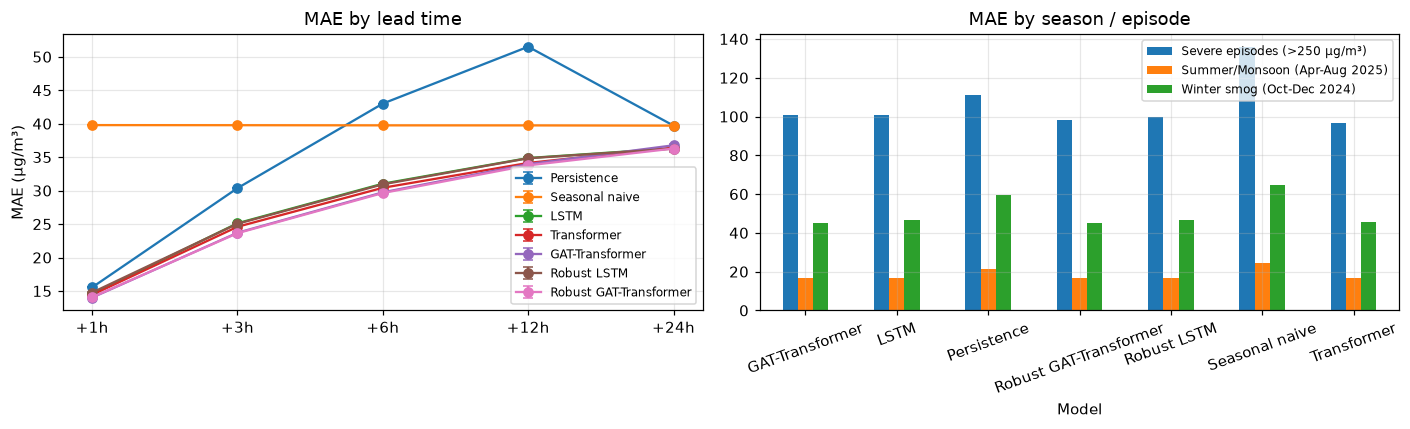

In [6]:
hz = pd.read_csv("results/metrics_horizon.csv")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, g in hz.groupby("Model", sort=False):
    ax[0].errorbar([f"+{h}h" for h in g.Horizon], g.MAE_mean, yerr=g.MAE_std, marker="o", label=name, capsize=3)
ax[0].set_title("MAE by lead time"); ax[0].set_ylabel("MAE (µg/m³)"); ax[0].legend(fontsize=8)
ss = pd.read_csv("results/metrics_season.csv").pivot(index="Model", columns="Subset", values="MAE_mean")
ss.plot.bar(ax=ax[1], rot=20); ax[1].set_title("MAE by season / episode"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Significance (Diebold–Mariano, GAT-Transformer vs others).** Negative statistic = GAT-Transformer has lower error.

In [7]:
dm = pd.read_csv("results/dm_test.csv")
dm.assign(cell=[f"{s:+.2f} (p={p:.3g})" for s, p in zip(dm["DM stat"], dm["p-value"])])   .pivot(index="Comparison", columns="Horizon", values="cell")

Horizon,1,3,6,12,24
Comparison,,,,,
GAT-Transformer vs LSTM,-10.60 (p=3.05e-26),-5.85 (p=4.77e-09),-2.88 (p=0.00394),-1.33 (p=0.185),+1.89 (p=0.0584)
GAT-Transformer vs Persistence,-20.05 (p=2.18e-89),-13.33 (p=1.45e-40),-12.50 (p=7.85e-36),-9.39 (p=6.14e-21),-1.94 (p=0.0529)
GAT-Transformer vs Robust GAT-Transformer,-0.34 (p=0.731),+1.93 (p=0.0535),+0.99 (p=0.322),+1.41 (p=0.159),+2.42 (p=0.0155)
GAT-Transformer vs Robust LSTM,-15.97 (p=2.06e-57),-6.57 (p=5.18e-11),-4.10 (p=4.09e-05),-1.53 (p=0.126),+1.11 (p=0.268)
GAT-Transformer vs Seasonal naive,-45.75 (p=0),-16.01 (p=1.02e-57),-8.29 (p=1.09e-16),-3.95 (p=7.86e-05),-1.94 (p=0.0529)
GAT-Transformer vs Transformer,-13.06 (p=5.9e-39),-4.03 (p=5.62e-05),-0.36 (p=0.718),+1.67 (p=0.0943),+0.88 (p=0.38)


## 5. Sensor-failure test
Each station's own readings are hidden in turn; the model must forecast it from neighbouring stations only.

In [8]:
sf = pd.read_csv("results/sensor_failure.csv")
tbl = sf.groupby("Model", sort=False)[["MAE_normal", "MAE_failed"]].mean().round(1)
tbl["Error increase"] = (tbl.MAE_failed / tbl.MAE_normal - 1).map(lambda v: "—" if not np.isfinite(v) else f"{v:+.0%}")
tbl

,MAE_normal,MAE_failed,Error increase
Model,,,
Station average,NaN,74.6,—
LSTM,28.2,55.4,+96%
Transformer,27.8,58.0,+109%
GAT-Transformer,27.8,54.5,+96%
Robust LSTM,28.4,42.4,+49%
Robust GAT-Transformer,27.4,31.5,+15%


## 6. Live forecast example
Anand Vihar, 18 Nov 2024 08:00 (test period, peak of the 2024 smog season), with the sensor working and
with a simulated sensor failure.

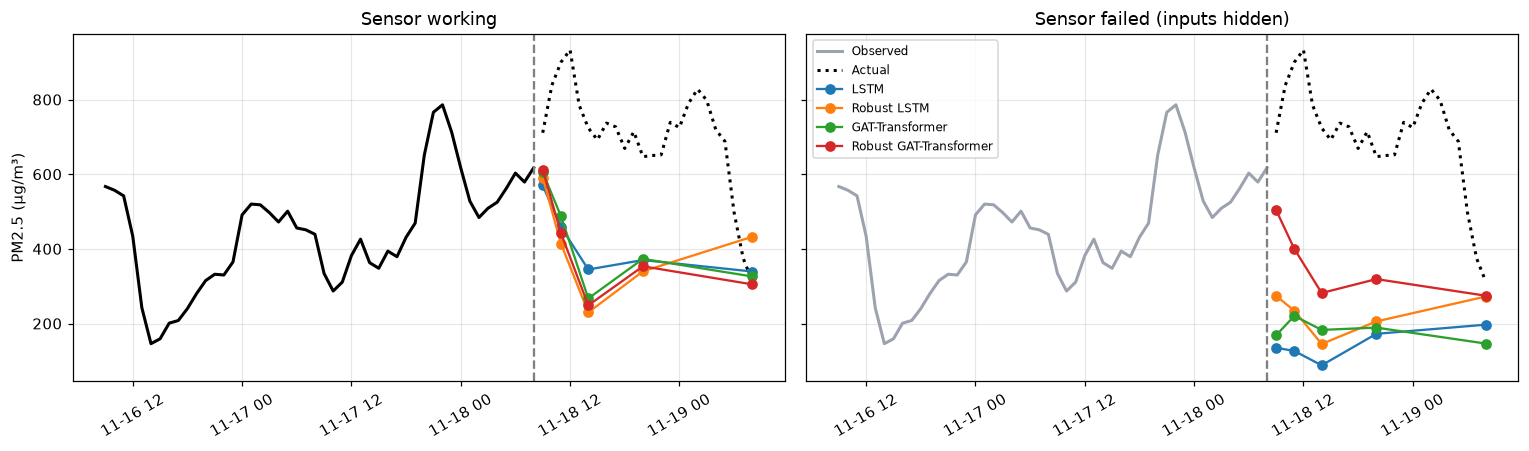

In [9]:
best = json.load(open("results/best_seeds.json"))
models = {n: load_model(n, int(best[n]), data) for n in ["LSTM", "Robust LSTM", "GAT-Transformer", "Robust GAT-Transformer"]}
names = st["name"].tolist(); j = names.index("Anand Vihar")
t = int(np.where(data.times == pd.Timestamp("2024-11-18 08:00"))[0][0])
X = data.features[t - 23: t + 1].unsqueeze(0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, failed in zip(axes, [False, True]):
    Xi = data.hide_stations(X, [j]) if failed else X
    hist = data.times[t - 47: t + 1]; fut = data.times[t + 1: t + 25]
    ax.plot(hist, data.pm25[t - 47: t + 1, j], color="#9CA3AF" if failed else "k", lw=2, label="Observed")
    ax.plot(fut, data.pm25[t + 1: t + 25, j], "k:", lw=2, label="Actual")
    with torch.no_grad():
        for n, m in models.items():
            p = data.denorm(m(Xi, data.adj).numpy()[0])[:, j]
            ax.plot([data.times[t] + pd.Timedelta(hours=h) for h in C.HORIZONS], p, marker="o", label=n)
    ax.axvline(data.times[t], ls="--", c="gray")
    ax.set_title("Sensor failed (inputs hidden)" if failed else "Sensor working"); ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("PM2.5 (µg/m³)"); axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()

## Conclusions
- All neural models beat the persistence baseline by about 22–24% MAE on unseen data.
- The **GAT-Transformer** is significantly better than LSTM and Transformer at short lead times (+1h, +3h); at +12/+24h the neural models are statistically tied.
- With **station dropout**, the **Robust GAT-Transformer** is the best model overall and keeps working when a station's sensor fails (+15% error vs +49% for the equally-trained LSTM), because it learns to use neighbouring stations.
- Limitations: winter peaks (Nov 2024 was more extreme than any training winter), no weather inputs, and the Jan–Mar 2025 gap in the source data.